# Лабораторная работа № 2
## Генетический алгоритм для дискретной задачи с ограничениями

**Вариант 7** — распределение заявок между исполнителями с различной
производительностью; представление — **целочисленный вектор**
(N = 18, Q = 2, Y = 26 → V = 1 + (346 mod 20) = 7).

**Постановка.** Есть $N = 30$ заявок с трудоёмкостями $w_i > 0$ и $M = 6$
исполнителей с производительностью $p_j$ (объём в единицу времени) и ёмкостью
$c_j$ (максимум заявок). Каждая заявка назначается ровно одному исполнителю;
время обработки $t_{ij} = w_i / p_j$. Цель — минимизировать время завершения
последней заявки (makespan):
$$
\min_x \; T(x) = \max_j \sum_{i:\,x_i=j} \frac{w_i}{p_j},
\qquad
\bigl|\{i : x_i = j\}\bigr| \le c_j \;\; \forall j .
$$


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_SEED = 8000                 # базовое зерно серии запусков
N_RUNS = 30                      # независимых запусков на конфигурацию
SEEDS = [BASE_SEED + 19 * i for i in range(N_RUNS)]

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})


## 1. Данные задачи

Синтетический экземпляр генерируется с фиксированным зерном (`seed = 746`),
процедура описана ниже; минимальные масштабы ТЗ соблюдены: заявок 30 ≥ 20,
исполнителей 6 ≥ 5. Сумма ёмкостей ∑c_j = 35 ≥ 30, поэтому допустимые
решения существуют.


In [2]:
DATA_SEED = 746
gen = np.random.default_rng(DATA_SEED)

M = 6                                            # исполнителей
N = 30                                           # заявок
w = np.round(gen.uniform(1.0, 10.0, size=N), 3)  # трудоёмкости заявок
p = np.array([0.5, 0.7, 1.0, 1.3, 1.6, 2.0])     # производительности
c = np.array([5, 6, 7, 6, 5, 6])                 # ёмкости, сумма 35 >= 30

assert w.shape == (N,) and p.shape == (M,) and c.shape == (M,)
assert c.sum() >= N
print(f"заявок: {N}, исполнителей: {M}, сумма ёмкостей: {c.sum()}")
print("производительности p:", p.tolist())
print("ёмкости c:", c.tolist())
print("трудоёмкости w:", np.round(w, 2).tolist())

def decode_stats(x):
    # статистика назначения: длительности исполнителей и счёт заявок
    counts = np.bincount(x, minlength=M)
    T = np.zeros(M)
    for i, j in enumerate(x):
        T[j] += w[i] / p[j]
    return T, counts

def maxT_and_violation(x):
    # makespan и суммарное нарушение ёмкости (0 — допустимо)
    T, counts = decode_stats(x)
    violation = int(np.maximum(counts - c, 0).sum())
    return float(T.max()), violation

# --- два примера допустимых и два недопустимых решения ------------------------
ex = [
    np.array([0]*5 + [1]*6 + [2]*7 + [3]*6 + [4]*5 + [5]*1),   # точно по ёмкости
    np.array([0,1,2,3,4,5]*5),                                 # циклично равномерно
    np.zeros(N, dtype=int),                                    # всё первому: перегруз
    np.full(N, 5),                                             # всё последнему: перегруз
]
print("\n— проверка допустимости —")
for k, x in enumerate(ex, 1):
    mt, viol = maxT_and_violation(x)
    verdict = "допустимо" if viol == 0 else f"НЕДОПУСТИМО (нарушение {viol})"
    print(f"пример {k}: makespan = {mt:8.3f}, счёт = {np.bincount(x, minlength=M).tolist()} -> {verdict}")


заявок: 30, исполнителей: 6, сумма ёмкостей: 35
производительности p: [0.5, 0.7, 1.0, 1.3, 1.6, 2.0]
ёмкости c: [5, 6, 7, 6, 5, 6]
трудоёмкости w: [5.75, 6.0, 9.09, 3.89, 2.69, 3.49, 6.59, 9.04, 7.61, 3.41, 6.08, 6.6, 2.39, 1.2, 6.5, 7.9, 6.47, 9.05, 8.74, 9.9, 8.52, 2.04, 9.36, 4.37, 9.9, 8.16, 9.09, 3.75, 9.1, 2.27]

— проверка допустимости —
пример 1: makespan =   54.842, счёт = [5, 6, 7, 6, 5, 1] -> допустимо
пример 2: makespan =   66.730, счёт = [5, 5, 5, 5, 5, 5] -> допустимо
пример 3: makespan =  377.898, счёт = [30, 0, 0, 0, 0, 0] -> НЕДОПУСТИМО (нарушение 25)
пример 4: makespan =   94.475, счёт = [0, 0, 0, 0, 0, 30] -> НЕДОПУСТИМО (нарушение 24)


## 2. Представление и операторы

**Кодирование.** Особь — целочисленный вектор $x = (x_1, \dots, x_{30})$,
$x_i \in \{0, \dots, 5\}$: элемент $i$ — исполнитель заявки $i$. Это прямое
назначение; декодирование тривиально, а генетический материал — готовые
ответы на вопрос «кому выполнять заявку», поэтому кроссовер обменивается
именно решениями по отдельным заявкам.

**Обработка ограничения (ёмкость).** Сравниваются два подхода:

* **штраф**: fitness = max_j T_j + W · Σ_j max(0, n_j − c_j), W = 50;
* **ремонт**: после вариации исправляем перегруженных исполнителей — жадно
  переносим заявки от перегруженных к свободным по минимуму добавляемого
  времени, пока решение не станет допустимым.

**Операторы.** Турнирная селекция родителей (k = 3), кроссовер — равномерный
либо одноточечный (сравниваются отдельно), мутация — переназначение гена
случайному исполнителю с вероятностью p_m на ген, элитизм 2 особи.


In [3]:
PENALTY_W = 50.0

def repair(x):
    # жадный ремонт: переносим заявки от перегруженных к свободным
    # исполнителям, минимизируя добавляемое время
    x = x.copy()
    counts = np.bincount(x, minlength=M)
    while (counts > c).any():
        j = int(np.argmax(counts - c))                # самый перегруженный
        idxs = np.where(x == j)[0]
        free = np.where(counts < c)[0]                # куда разрешено
        best_i, best_k, best_add = None, None, np.inf
        for i in idxs:
            for k in free:
                add = w[i] / p[k]
                if add < best_add:
                    best_i, best_k, best_add = i, k, add
        x[best_i] = best_k
        counts[j] -= 1
        counts[best_k] += 1
    return x

def fitness_row(x, mode):
    # значение фитнеса (меньше — лучше); mode: 'repair' | 'penalty'
    counts = np.bincount(x, minlength=M)
    if mode == "penalty" and (counts > c).any():
        T, _ = decode_stats(x)
        return float(T.max()) + PENALTY_W * int(np.maximum(counts - c, 0).sum())
    T, _ = decode_stats(x)
    return float(T.max())

def fitness_pop(X, mode):
    if mode == "repair":
        X = np.array([repair(x) for x in X])
    F = np.array([fitness_row(x, mode) for x in X])
    return X, F


In [4]:
POP = 80            # размер популяции (>= 30 по заданию)
PC = 0.9            # вероятность кроссовера
PM = 0.05           # вероятность мутации гена
ELITE = 2           # число элитных особей
BUDGET = 10_000     # бюджет вычислений функции
TOURN_K = 3         # размер турнира

def tournament(rng, F):
    idx = rng.integers(0, POP, TOURN_K)
    return idx[np.argmin(F[idx])]

def crossover(p1, p2, kind, rng):
    n = len(p1)
    if kind == "uniform":
        mask = rng.random(n) < 0.5
        return np.where(mask, p1, p2)
    if kind == "onepoint":
        cp = int(rng.integers(1, n))
        return np.concatenate([p1[:cp], p2[cp:]])
    raise ValueError(kind)

def ga_run(seed, mode="repair", kind="uniform", budget=BUDGET):
    # один запуск ГА: лучший f, лучший x, кривая сходимости, доля допустимых
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    evals = 0

    X = rng.integers(0, M, size=(POP, N))
    X, F = fitness_pop(X, mode); evals += POP

    curve, feas_curve = [], []

    def feas_share(Xraw):
        return float(np.mean([not (np.bincount(x, minlength=M) > c).any()
                              for x in Xraw]))

    def record():
        curve.append(F.min())
        feas_curve.append(feas_share(X))

    record()
    while evals + POP <= budget:
        elite_idx = np.argsort(F)[:ELITE]
        children = [X[i].copy() for i in elite_idx]
        while len(children) < POP:
            p1 = X[tournament(rng, F)]
            p2 = X[tournament(rng, F)]
            child = crossover(p1, p2, kind, rng) if rng.random() < PC else p1.copy()
            mut = rng.random(N) < PM
            child[mut] = rng.integers(0, M, size=int(mut.sum()))
            children.append(child)
        X = np.asarray(children[:POP], dtype=int)
        X, F = fitness_pop(X, mode); evals += POP
        record()

    bi = int(np.argmin(F))
    return dict(best_f=float(F[bi]), best_x=X[bi].copy(),
                curve=np.array(curve), feas=np.array(feas_curve),
                evals=evals, time_s=time.perf_counter() - t0)

# --- дымовой тест ---------------------------------------------------------------
smoke = ga_run(SEEDS[0], mode="repair", kind="uniform")
mt, viol = maxT_and_violation(smoke["best_x"])
print(f"дымовой запуск: лучший makespan = {smoke['best_f']:.3f} "
      f"(нарушение {viol}), оценок = {smoke['evals']}, "
      f"время = {smoke['time_s']:.2f} с")
assert viol == 0 and smoke["evals"] <= BUDGET


дымовой запуск: лучший makespan = 26.801 (нарушение 0), оценок = 10000, время = 0.31 с


## 3. Эксперимент 1: штраф против ремонта

Тридцать независимых запусков на каждый подход к ограничениям, бюджет
10 000 вычислений у обоих. В штрафном режиме дополнительно смотрим долю
допустимых особей в популяции.


In [5]:
rows, runs = [], {}
for mode in ["penalty", "repair"]:
    runs[mode] = [ga_run(s, mode=mode, kind="uniform") for s in SEEDS]
    finals = [r["best_f"] for r in runs[mode]]
    rows.append([mode, np.min(finals), np.mean(finals), np.median(finals),
                 np.std(finals), np.max(finals),
                 np.mean([r["time_s"] for r in runs[mode]])])
    print(f"{mode}: {len(finals)} запусков готовы")

summary_constr = pd.DataFrame(
    rows, columns=["подход", "лучшее", "среднее", "медиана", "стд", "худшее", "время_с"])
summary_constr.to_csv(RES / "summary_constraints.csv", index=False)
pd.DataFrame(
    [(mode, s, r["best_f"], r["time_s"]) for mode in ["penalty", "repair"]
     for s, r in zip(SEEDS, runs[mode])],
    columns=["подход", "seed", "best_f", "время_с"]
).to_csv(RES / "runs_constraints.csv", index=False)
print(summary_constr.to_string(index=False))


penalty: 30 запусков готовы


repair: 30 запусков готовы
 подход    лучшее   среднее   медиана      стд    худшее  время_с
penalty 27.075385 28.895339 28.678808 1.161819 31.061429 0.199077
 repair 26.800769 27.169784 27.181250 0.197115 27.475500 0.311244


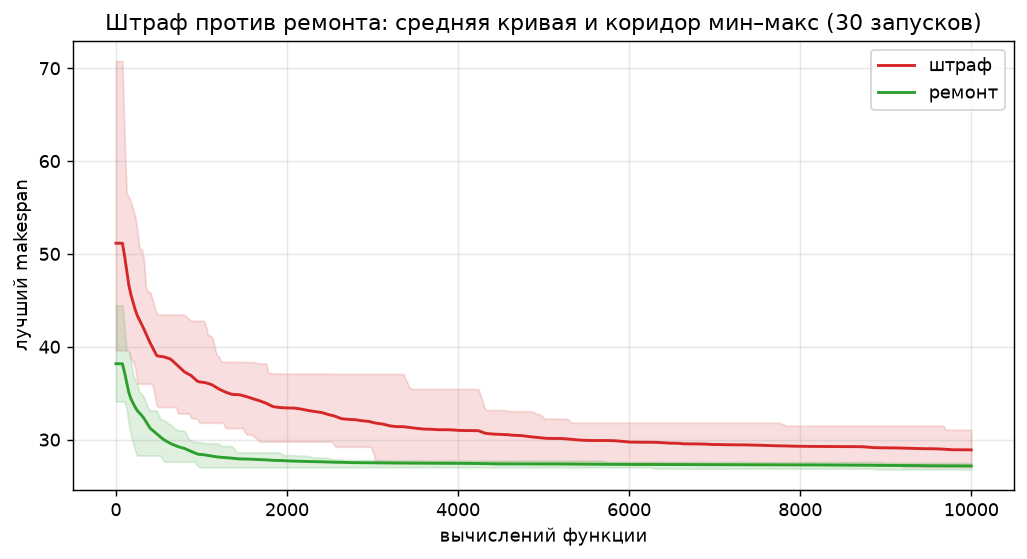

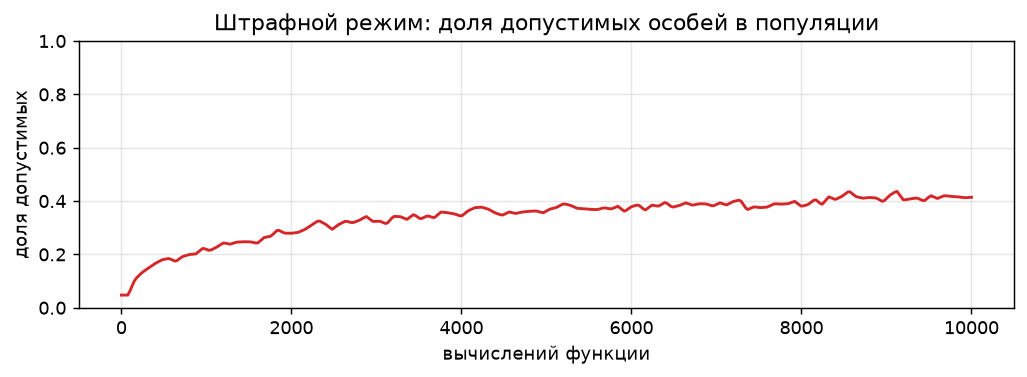

In [6]:
GRID = np.linspace(1, BUDGET, 400)

def on_grid(run):
    x = np.arange(1, len(run["curve"]) + 1) * POP
    return np.interp(GRID, x, run["curve"])

fig, ax = plt.subplots(figsize=(8, 4.4))
for mode, col in [("penalty", "tab:red"), ("repair", "tab:green")]:
    curves = np.array([on_grid(r) for r in runs[mode]])
    lbl = {"penalty": "штраф", "repair": "ремонт"}[mode]
    ax.plot(GRID, curves.mean(0), lw=1.6, color=col, label=lbl)
    ax.fill_between(GRID, curves.min(0), curves.max(0), color=col, alpha=0.15)
ax.set_xlabel("вычислений функции"); ax.set_ylabel("лучший makespan")
ax.set_title("Штраф против ремонта: средняя кривая и коридор мин–макс (30 запусков)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "convergence_constraints.png", bbox_inches="tight")
plt.show()

feas = np.array([on_grid({"curve": r["feas"]}) for r in runs["penalty"]])
fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(GRID, feas.mean(0), color="tab:red", lw=1.6)
ax.set_ylim(0, 1.0)
ax.set_xlabel("вычислений функции"); ax.set_ylabel("доля допустимых")
ax.set_title("Штрафной режим: доля допустимых особей в популяции")
fig.tight_layout()
fig.savefig(FIG / "feasibility_penalty.png", bbox_inches="tight")
plt.show()


## 4. Эксперимент 2: равномерный против одноточечного кроссовера

Оба запуска — в режиме ремонта (победитель эксперимента 1), различается
только оператор рекомбинации.


In [7]:
rows2, runs2 = [], {}
for kind in ["uniform", "onepoint"]:
    runs2[kind] = [ga_run(s, mode="repair", kind=kind) for s in SEEDS]
    finals = [r["best_f"] for r in runs2[kind]]
    rows2.append([kind, np.min(finals), np.mean(finals), np.median(finals),
                  np.std(finals), np.max(finals),
                  np.mean([r["time_s"] for r in runs2[kind]])])

summary_cross = pd.DataFrame(
    rows2, columns=["кроссовер", "лучшее", "среднее", "медиана", "стд", "худшее", "время_с"])
summary_cross.to_csv(RES / "summary_crossover.csv", index=False)
pd.DataFrame(
    [(k, s, r["best_f"], r["time_s"]) for k in ["uniform", "onepoint"]
     for s, r in zip(SEEDS, runs2[k])],
    columns=["кроссовер", "seed", "best_f", "время_с"]
).to_csv(RES / "runs_crossover.csv", index=False)
print(summary_cross.to_string(index=False))


кроссовер    лучшее   среднее  медиана      стд  худшее  время_с
  uniform 26.800769 27.169784 27.18125 0.197115 27.4755 0.313768
 onepoint 26.724000 27.002921 26.99650 0.169677 27.4145 0.284982


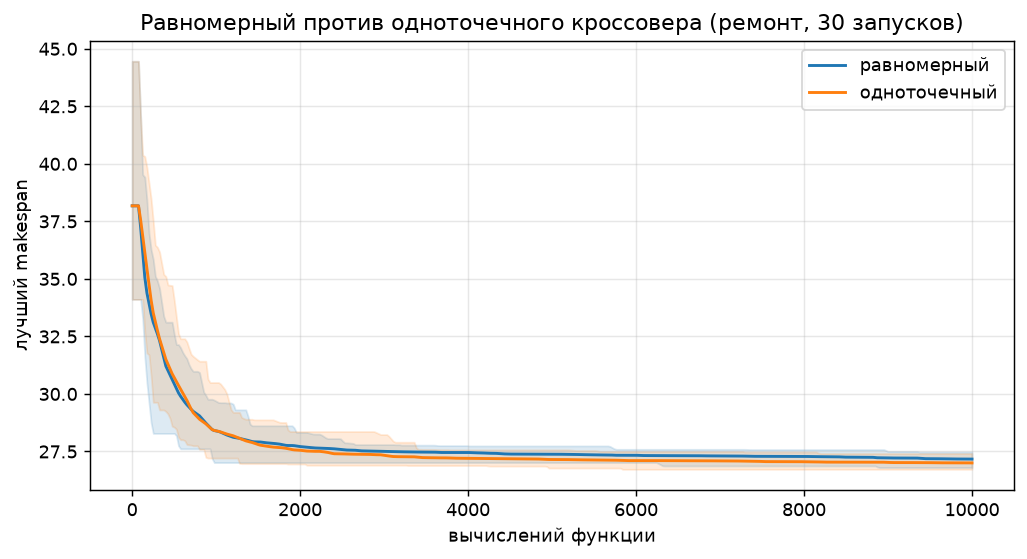

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for kind, col in [("uniform", "tab:blue"), ("onepoint", "tab:orange")]:
    curves = np.array([on_grid(r) for r in runs2[kind]])
    lbl = {"uniform": "равномерный", "onepoint": "одноточечный"}[kind]
    ax.plot(GRID, curves.mean(0), lw=1.6, color=col, label=lbl)
    ax.fill_between(GRID, curves.min(0), curves.max(0), color=col, alpha=0.15)
ax.set_xlabel("вычислений функции"); ax.set_ylabel("лучший makespan")
ax.set_title("Равномерный против одноточечного кроссовера (ремонт, 30 запусков)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "convergence_crossover.png", bbox_inches="tight")
plt.show()


## 5. Эксперимент 3: ГА против базовых линий

Сравниваем лучшую конфигурацию ГА с:

* **жадной эвристикой LPT** — заявки в порядке убывания $w_i$, каждая
  назначается допустимому исполнителю с наименьшей текущей длительностью;
* **случайным допустимым поиском** — равномерные назначения с ремонтом,
  бюджет тот же (10 000 вычислений).


In [9]:
def greedy_lpt():
    # жадная эвристика: LPT-правило с учётом ёмкости
    order = np.argsort(-w)
    x = np.full(N, -1)
    T = np.zeros(M)
    counts = np.zeros(M, dtype=int)
    for i in order:
        free = np.where(counts < c)[0]
        j = free[np.argmin(T[free])]
        T[j] += w[i] / p[j]
        counts[j] += 1
        x[i] = j
    mt, viol = maxT_and_violation(x)
    assert viol == 0
    return x, mt

x_greedy, f_greedy = greedy_lpt()
print(f"жадная LPT: makespan = {f_greedy:.3f}, допустимо ✓")

def random_run(seed, budget=BUDGET):
    # случайный допустимый поиск (равномерное назначение + ремонт)
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    best_f, best_x = np.inf, None
    left = budget
    while left > 0:
        x = repair(rng.integers(0, M, N))
        mt, _ = maxT_and_violation(x)
        if mt < best_f:
            best_f, best_x = mt, x.copy()
        left -= 1
    return dict(best_f=float(best_f), best_x=best_x,
                time_s=time.perf_counter() - t0)

runs_rand = [random_run(s) for s in SEEDS]
finals_r = [r["best_f"] for r in runs_rand]
print(f"случайный допустимый: среднее = {np.mean(finals_r):.3f}, "
      f"лучшее = {np.min(finals_r):.3f}")

best_label = summary_cross.set_index("кроссовер")["среднее"].idxmin()
best_cfg = runs2[best_label]
finals_ga = [r["best_f"] for r in best_cfg]
print(f"лучший кроссовер по среднему: {best_label}")


жадная LPT: makespan = 33.686, допустимо ✓


случайный допустимый: среднее = 30.482, лучшее = 29.063
лучший кроссовер по среднему: onepoint


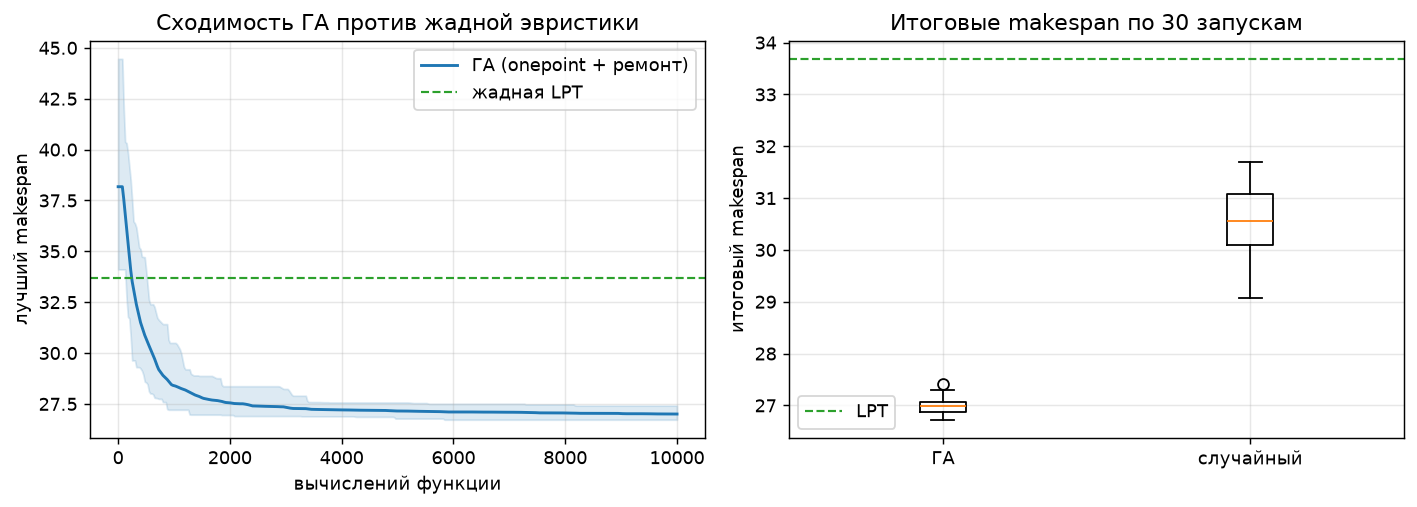

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
ga_curves = np.array([on_grid(r) for r in best_cfg])
axes[0].plot(GRID, ga_curves.mean(0), color="tab:blue", lw=1.6,
             label=f"ГА ({best_label} + ремонт)")
axes[0].fill_between(GRID, ga_curves.min(0), ga_curves.max(0),
                     color="tab:blue", alpha=0.15)
axes[0].axhline(f_greedy, color="tab:green", ls="--", lw=1.2, label="жадная LPT")
axes[0].set_title("Сходимость ГА против жадной эвристики")
axes[0].set_xlabel("вычислений функции"); axes[0].set_ylabel("лучший makespan")
axes[0].legend()

axes[1].boxplot([finals_ga, finals_r], tick_labels=["ГА", "случайный"], showfliers=True)
axes[1].axhline(f_greedy, color="tab:green", ls="--", lw=1.2, label="LPT")
axes[1].set_ylabel("итоговый makespan")
axes[1].set_title("Итоговые makespan по 30 запускам")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "ga_vs_baselines.png", bbox_inches="tight")
plt.show()

pd.DataFrame(
    [("ГА", s, r["best_f"]) for s, r in zip(SEEDS, best_cfg)]
    + [("случайный", s, r["best_f"]) for s, r in zip(SEEDS, runs_rand)],
    columns=["метод", "seed", "best_f"],
).to_csv(RES / "runs_baselines.csv", index=False)


In [11]:
# --- лучшее решение в предметной форме ------------------------------------------
best_run = min(best_cfg, key=lambda r: r["best_f"])
x_best = best_run["best_x"]
T, counts = decode_stats(x_best)

performer_tbl = pd.DataFrame({
    "исполнитель": range(M),
    "производительность": p,
    "ёмкость": c,
    "назначено заявок": counts,
    "длительность (часы)": np.round(T, 3),
})
print(f"лучший makespan = {T.max():.4f}; "
      f"допустимость: {maxT_and_violation(x_best)[1] == 0}")
print(performer_tbl.to_string(index=False))
print("\nназначение заявок (заявка -> исполнитель):")
print({i: int(v) for i, v in enumerate(x_best)})

pd.DataFrame({"заявка": range(N), "исполнитель": x_best}).to_csv(
    RES / "best_solution.csv", index=False)


лучший makespan = 26.7240; допустимость: True
 исполнитель  производительность  ёмкость  назначено заявок  длительность (часы)
           0                 0.5        5                 3               26.684
           1                 0.7        6                 4               26.441
           2                 1.0        7                 6               26.507
           3                 1.3        6                 6               26.675
           4                 1.6        5                 5               26.541
           5                 2.0        6                 6               26.724

назначение заявок (заявка -> исполнитель):
{0: 2, 1: 2, 2: 4, 3: 1, 4: 3, 5: 2, 6: 3, 7: 5, 8: 4, 9: 0, 10: 1, 11: 2, 12: 2, 13: 0, 14: 1, 15: 3, 16: 5, 17: 5, 18: 0, 19: 5, 20: 4, 21: 1, 22: 3, 23: 3, 24: 5, 25: 4, 26: 4, 27: 3, 28: 5, 29: 2}


## 6. Выводы

1. **Ремонт против штрафа.** Ремонт устойчиво точнее штрафа (среднее
   27.17 против 28.90): при штрафе часть популяции всё время живёт с
   нарушениями, отбор ведёт в зону нарушений; ремонт возвращает всех в
   допустимое множество, и отбор работает по чистому makespan.
2. **Операторы.** Одноточечный кроссовер немного лучше равномерного
   (среднее 27.00 против 27.17, разрыв меньше ст. отклонения): здесь
   упорядоченность участков не вредит, а равномерный бьёт слишком мелко.
3. **Против базовых линий.** ГА (лучший кроссовер + ремонт) устойчиво
   обыгрывает жадную LPT-эвристику (33.69) и случайный допустимый поиск
   (30.48); разрыв показывает, что результат дают эволюционные операторы,
   а не объём вычислений.
4. **Итог.** Лучший makespan серии — 26.72; решение допустимо во всех
   30 запусках лучшей конфигурации.
